# GT 수정 비교: 2026-10-01 → 2026-10-09

- 최초 GT: 10월 1일 학습에 사용한 Exposure 라벨.
- 직전 GT: 10월 9일 10:32 JSON. 수정 GT: 당시 다운로드하여 고정한 GT.
- 86개 촬영본, 유효 타일 1,791개, P1/P2/P3 258개. 현재 changed_v3·Gold72와는 비교 대상이 다르다.
- 함침율 = `100 × (1 − Exposure 픽셀 수 / 65,536)`. Exposure는 `alpha > 0`.
- 변화량 Δ = **수정 GT − 최초 GT**, 단위 **pp**. 음수는 미함침 증가, 양수는 미함침 감소.
- 여기의 000/180은 **당시 촬영 방향**이다. v3의 사용자 지정 180° 회전과 구분한다.

아래 설정을 바꾸고 위에서부터 실행하면 표와 그림을 다시 그릴 수 있다.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import math
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from PIL import Image
from IPython.display import display

# 작업 폴더가 달라도 같은 프로젝트를 찾는다.
candidates = [Path.cwd(), *Path.cwd().parents, Path(r"D:\Code\vision_data")]
ROOT = next((p for p in candidates
             if (p / "analysis/downloaded_gt_comparison_all_20261009/summary.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("10월 1일/10월 9일 GT 비교 자료가 있는 프로젝트 폴더를 지정하세요.")
SOURCE = ROOT / "analysis/downloaded_gt_comparison_all_20261009"
OUT = ROOT / "analysis/261012/gt_revision_figures"

MASK_TASKS = [616, 641]         # 원본 Task ID. 변경 사례: 616,617,622,636,638,639,640,641,647,673
SHOW_ALL_CAPTURE_TABLES = True # 86개 촬영본의 Δ 표도 모두 표시
ROWS_PER_PAGE = 24
SAVE_FIGURES = True            # PNG 300 dpi + PDF

font_path = Path("C:/Windows/Fonts/malgun.ttf")
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    font_name = font_manager.FontProperties(fname=str(font_path)).get_name()
else:
    font_name = "DejaVu Sans"

plt.rcParams.update({
    "font.family": font_name, "font.size": 10,
    "axes.unicode_minus": False, "axes.spines.top": False,
    "axes.spines.right": False, "axes.linewidth": 0.7,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 110, "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
POINTS = ["P1", "P2", "P3"]
POINT_COLORS = ["#486b8a", "#b37b46", "#66816a"]
ADDED_COLOR = "#bd7848"
REMOVED_COLOR = "#547fa1"

def read_json(name):
    return json.loads((SOURCE / name).read_text(encoding="utf-8-sig"))

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def show_figure(fig, name):
    if SAVE_FIGURES:
        OUT.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
        fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    display(fig)
    plt.close(fig)

def plot_table(frame, title, filename, width=13, formats=None, note=None, font_size=9):
    # 흰 배경과 수평선만 사용한 Matplotlib 표.
    formats = formats or {}
    values = []
    for _, row in frame.iterrows():
        line = []
        for name in frame.columns:
            value = row[name]
            if pd.isna(value):
                line.append("")
            elif name in formats:
                line.append(formats[name](value))
            elif isinstance(value, (int, np.integer)):
                line.append(f"{value:,}")
            elif isinstance(value, (float, np.floating)):
                line.append(f"{value:.4f}")
            else:
                line.append(str(value))
        values.append(line)
    row_height = 0.30
    body_height = row_height * (len(frame) + 1)
    bottom_margin = 0.50 if note else 0.22
    height = body_height + bottom_margin + 0.50
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_position([0.025, bottom_margin / height, 0.95, body_height / height])
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=11, fontweight="normal", pad=12)
    def text_units(text):
        return sum(2 if unicodedata.east_asian_width(c) in ("W", "F") else 1 for c in str(text))
    column_units = [max(text_units(name), *(text_units(row[j]) for row in values)) + 3
                    for j, name in enumerate(frame.columns)]
    column_widths = np.asarray(column_units, dtype=float) / sum(column_units)
    table = ax.table(cellText=values, colLabels=list(frame.columns),
                     cellLoc="right", colLoc="center", colWidths=column_widths,
                     bbox=[0, 0, 1, 1], edges="open")
    table.auto_set_font_size(False)
    table.set_fontsize(font_size)
    for (row, column), item in table.get_celld().items():
        item.set_facecolor("white")
        item.set_edgecolor("#333333" if row == 0 else "#b9b9b9")
        item.set_linewidth(0.7 if row == 0 else 0.25)
        item.visible_edges = "TB" if row == 0 else "B"
        if row == 0:
            item.get_text().set_fontweight("normal")
        elif column == 0:
            item.get_text().set_ha("left")
    if note:
        fig.text(0.025, 0.12 / height, note, fontsize=8, ha="left", va="bottom")
    show_figure(fig, filename)

In [2]:
summary = read_json("summary.json")
points = pd.DataFrame(read_json("point_comparison.json"))
tiles = pd.DataFrame(read_json("tile_comparison.json"))
tasks = pd.DataFrame(read_json("task_audit.json"))
source_files = ["summary.json", "point_comparison.json", "tile_comparison.json", "task_audit.json"]
SOURCE_HASHES = {name: file_hash(SOURCE / name) for name in source_files}

assert summary["complete_dataset"] and len(tasks) == 86
assert len(points) == 258 and len(tiles) == 1791
assert not points.duplicated(["task_id", "point"]).any()
assert (points.groupby("task_id")["point"].nunique() == 3).all()
for frame in [points, tiles]:
    assert (frame["pixels"] == 65536).all()
    assert (frame["added_exposure_pixels"] + frame["removed_exposure_pixels"] == frame["changed_pixels"]).all()
    np.testing.assert_allclose(frame["training_gt_pct"], 100 * (1 - frame["old_exposure_pixels"] / 65536))
    np.testing.assert_allclose(frame["download_gt_pct"], 100 * (1 - frame["new_exposure_pixels"] / 65536))
    np.testing.assert_allclose(frame["download_minus_training_pp"],
                               100 * (frame["removed_exposure_pixels"] - frame["added_exposure_pixels"]) / 65536)
    assert (frame["previous_binary_changed_pixels"] == 0).all()
    np.testing.assert_allclose(frame["previous_gt_pct"], frame["download_gt_pct"])
assert (points["image_changed_pixels"] == 0).all()
assert int((tasks["training_full_changed_pixels"] > 0).sum()) == summary["training_changed_tasks"]
assert int((tiles["changed_pixels"] > 0).sum()) == summary["training_changed_tiles"]

def add_identity(frame):
    result = frame.copy()
    result["case_number"] = result["case"].str.extract(r"case(\d+)")[0].astype(int)
    result["side"] = np.where(result["case"].str.contains("이동"), "이동측", "고정측")
    result["specimen_label"] = result["specimen"].astype(str).str.zfill(2)
    return result

points = add_identity(points)
tasks = add_identity(tasks)
print(f"촬영본 {len(tasks)}개 / 유효 타일 {len(tiles):,}개 / P1·P2·P3 {len(points)}개")
print(f"최초 GT 대비 변경: 촬영본 {summary['training_changed_tasks']}개, 타일 {summary['training_changed_tiles']}개")
print("직전 JSON GT와 다운로드 GT의 alpha·이진 마스크 차이: 0픽셀")

촬영본 86개 / 유효 타일 1,791개 / P1·P2·P3 258개
최초 GT 대비 변경: 촬영본 10개, 타일 155개
직전 JSON GT와 다운로드 GT의 alpha·이진 마스크 차이: 0픽셀


## 비교 범위와 집계

전체 캔버스의 변경 픽셀 수와 256×256 유효 타일의 변경 수를 구분한다.
함침율은 타일에서만 계산한다. 아래 표의 Δ는 모델 예측 오차가 아니라 **두 GT의 함침율 차이**다.

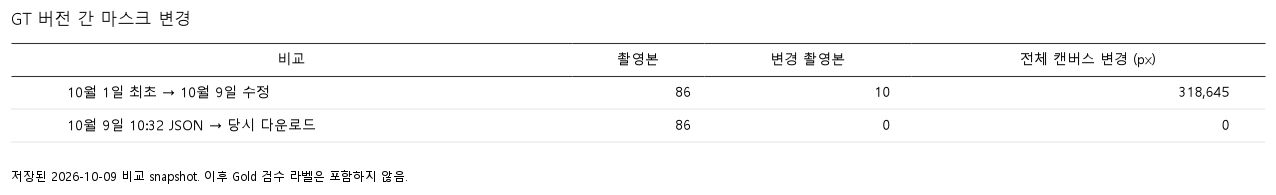

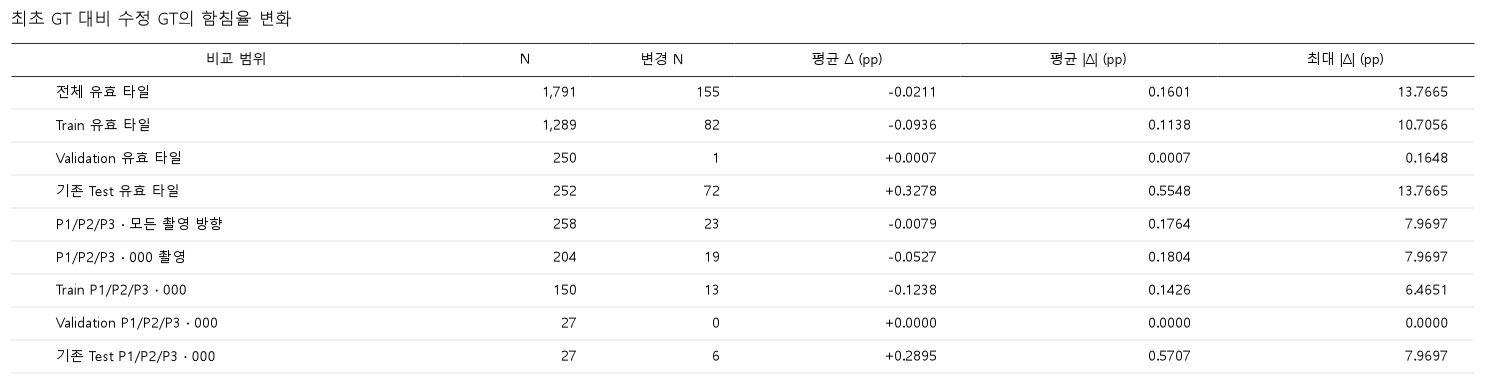

In [3]:
version_table = pd.DataFrame([
    {"비교": "10월 1일 최초 → 10월 9일 수정", "촬영본": 86,
     "변경 촬영본": summary["training_changed_tasks"],
     "전체 캔버스 변경 (px)": summary["training_vs_download_full_changed_pixels"]},
    {"비교": "10월 9일 10:32 JSON → 당시 다운로드", "촬영본": 86,
     "변경 촬영본": int((tasks["previous_binary_changed_pixels"] > 0).sum()),
     "전체 캔버스 변경 (px)": summary["previous_vs_download_binary_changed_pixels"]},
])
plot_table(version_table, "GT 버전 간 마스크 변경", "01_gt_versions", width=12,
           note="저장된 2026-10-09 비교 snapshot. 이후 Gold 검수 라벨은 포함하지 않음.")

scope_specs = [
    ("전체 유효 타일", tiles),
    ("Train 유효 타일", tiles[tiles["split"] == "train"]),
    ("Validation 유효 타일", tiles[tiles["split"] == "val"]),
    ("기존 Test 유효 타일", tiles[tiles["split"] == "test"]),
    ("P1/P2/P3 · 모든 촬영 방향", points),
    ("P1/P2/P3 · 000 촬영", points[points["direction"] == "000"]),
    ("Train P1/P2/P3 · 000", points[(points["direction"] == "000") & (points["split"] == "train")]),
    ("Validation P1/P2/P3 · 000", points[(points["direction"] == "000") & (points["split"] == "val")]),
    ("기존 Test P1/P2/P3 · 000", points[(points["direction"] == "000") & (points["split"] == "test")]),
]
scope_table = pd.DataFrame([{
    "비교 범위": label, "N": len(frame),
    "변경 N": int((frame["changed_pixels"] > 0).sum()),
    "평균 Δ (pp)": frame["download_minus_training_pp"].mean(),
    "평균 |Δ| (pp)": frame["download_minus_training_pp"].abs().mean(),
    "최대 |Δ| (pp)": frame["download_minus_training_pp"].abs().max(),
} for label, frame in scope_specs])
plot_table(scope_table, "최초 GT 대비 수정 GT의 함침율 변화", "02_scope_summary", width=14,
           formats={"평균 Δ (pp)": lambda x: f"{x:+.4f}"})

## Case·시편별 표

첫 표는 **전체 캔버스가 변경된 10개 촬영본**이다. 그중 P1/P2/P3가 바뀌지 않은 촬영본도 포함한다.
두 번째 표는 마스크가 바뀐 23개 중앙 지점의 최초·직전·수정 GT와 추가/제거 픽셀이다.

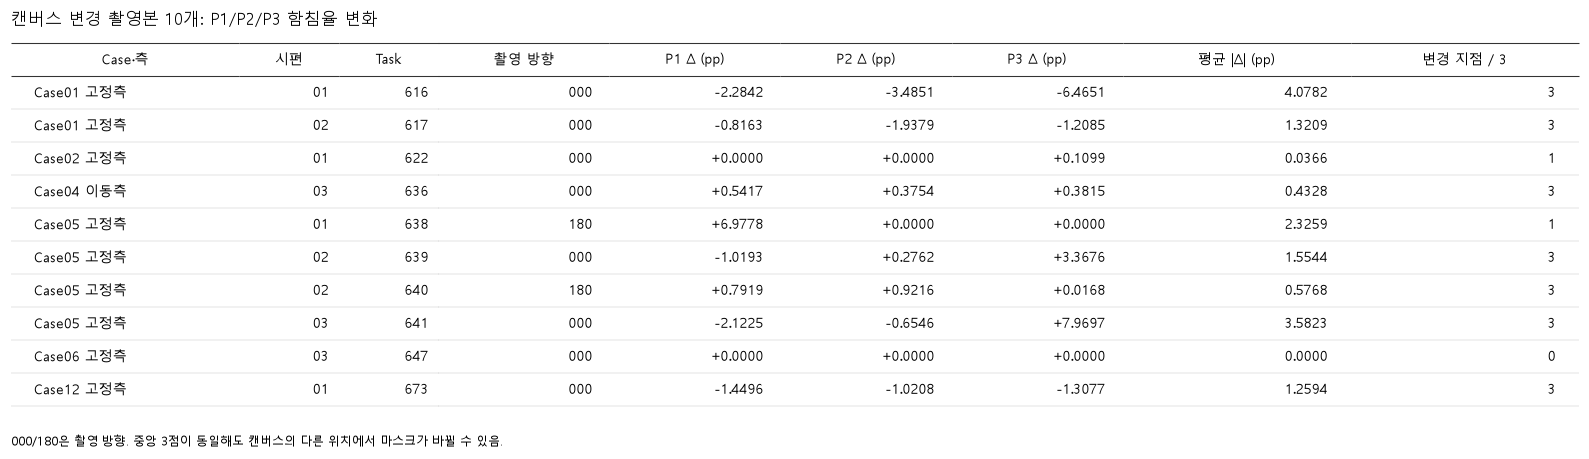

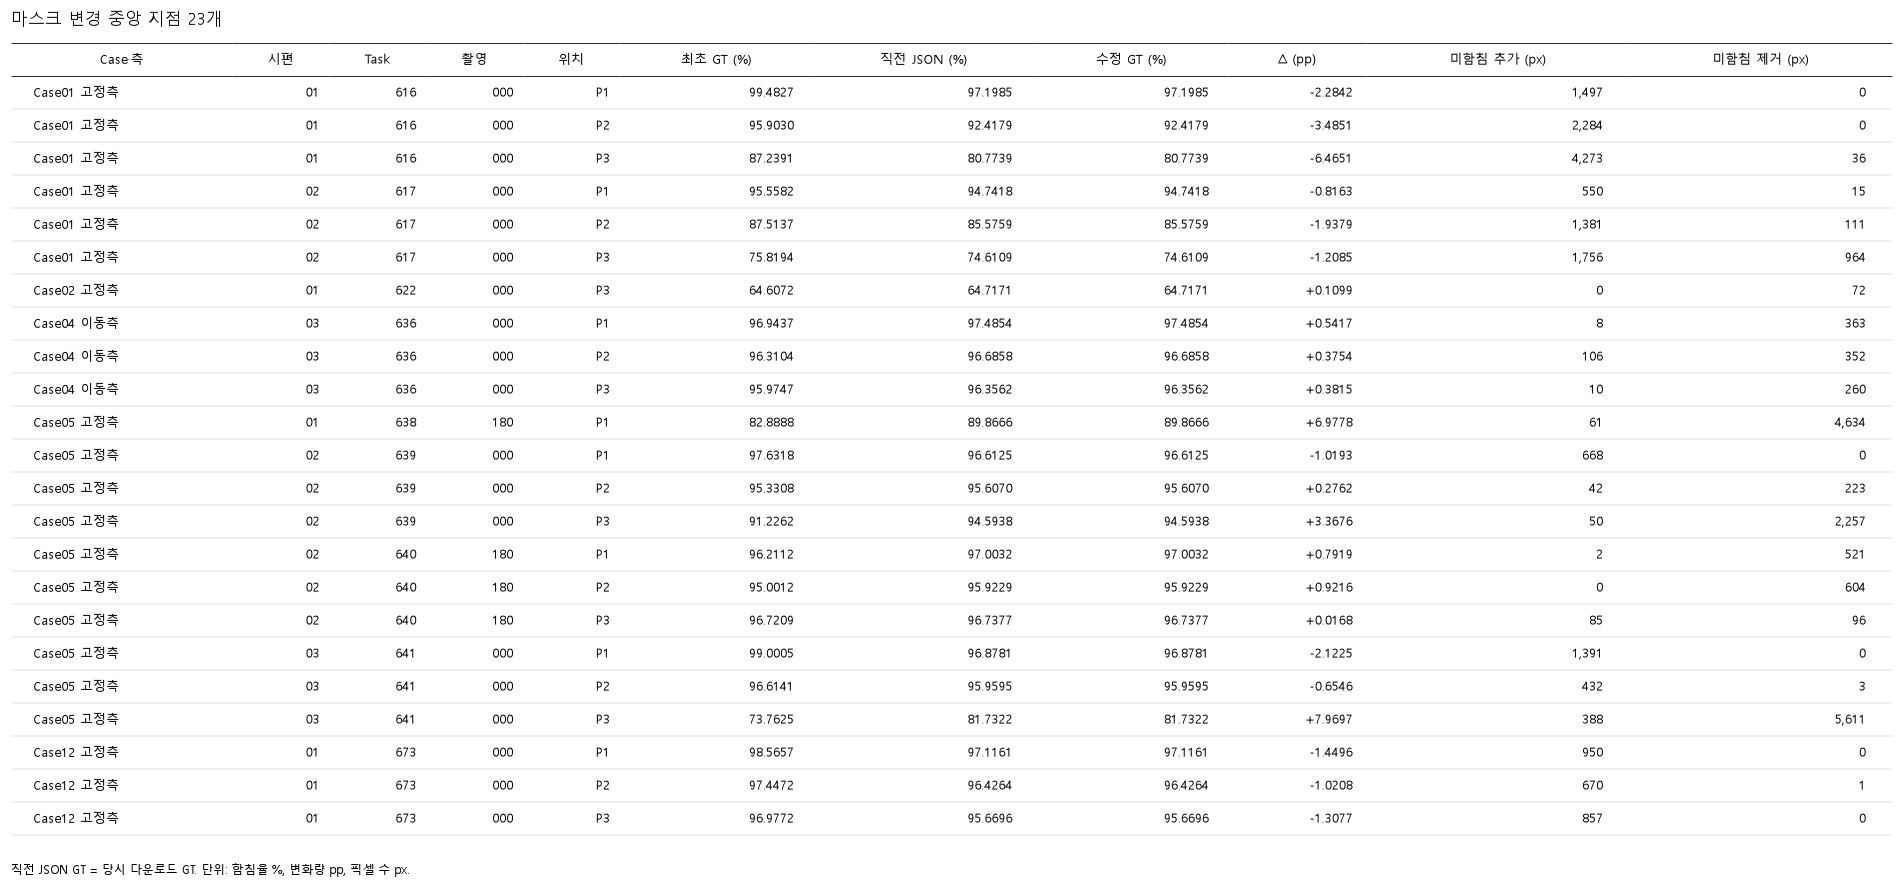

In [4]:
delta_wide = points.pivot(index="task_id", columns="point", values="download_minus_training_pp").reindex(columns=POINTS)
capture_data = tasks.merge(delta_wide, left_on="task_id", right_index=True, validate="one_to_one")
capture_data = capture_data.sort_values(["case_number", "side", "specimen_label", "direction", "task_id"])
capture_data["mean_abs_p123_pp"] = capture_data[POINTS].abs().mean(axis=1)

def capture_frame(frame):
    result = pd.DataFrame(index=frame.index)
    result["Case·측"] = frame["case_number"].map(lambda x: f"Case{x:02d}") + " " + frame["side"]
    result["시편"] = frame["specimen_label"]
    result["Task"] = frame["task_id"]
    result["촬영 방향"] = frame["direction"]
    for name in POINTS:
        result[f"{name} Δ (pp)"] = frame[name]
    result["평균 |Δ| (pp)"] = frame["mean_abs_p123_pp"]
    result["변경 지점 / 3"] = frame["changed_points"]
    return result.reset_index(drop=True)

changed_captures = capture_data[capture_data["training_full_changed_pixels"] > 0]
changed_capture_table = capture_frame(changed_captures)
delta_formats = {f"{p} Δ (pp)": lambda x: f"{x:+.4f}" for p in POINTS}
plot_table(changed_capture_table, "캔버스 변경 촬영본 10개: P1/P2/P3 함침율 변화", "03_changed_captures",
           width=15, formats=delta_formats,
           note="000/180은 촬영 방향. 중앙 3점이 동일해도 캔버스의 다른 위치에서 마스크가 바뀔 수 있음.")

changed_points = points[points["changed_pixels"] > 0].sort_values(
    ["case_number", "side", "specimen_label", "direction", "task_id", "point"])
point_table = pd.DataFrame({
    "Case·측": changed_points["case_number"].map(lambda x: f"Case{x:02d}") + " " + changed_points["side"],
    "시편": changed_points["specimen_label"], "Task": changed_points["task_id"],
    "촬영": changed_points["direction"], "위치": changed_points["point"],
    "최초 GT (%)": changed_points["training_gt_pct"],
    "직전 JSON (%)": changed_points["previous_gt_pct"],
    "수정 GT (%)": changed_points["download_gt_pct"],
    "Δ (pp)": changed_points["download_minus_training_pp"],
    "미함침 추가 (px)": changed_points["added_exposure_pixels"],
    "미함침 제거 (px)": changed_points["removed_exposure_pixels"],
}).reset_index(drop=True)
plot_table(point_table, f"마스크 변경 중앙 지점 {len(point_table)}개", "04_changed_point_values",
           width=18, formats={"Δ (pp)": lambda x: f"{x:+.4f}"}, font_size=8.5,
           note="직전 JSON GT = 당시 다운로드 GT. 단위: 함침율 %, 변화량 pp, 픽셀 수 px.")

## 함침율 변화 그래프

왼쪽(음수)은 미함침이 늘어난 지점, 오른쪽(양수)은 미함침이 줄어든 지점이다.
산점도의 대각선은 두 GT의 함침율이 같은 위치다. 그림에는 원래 수치를 사용하며 위치를 흔들지 않는다.

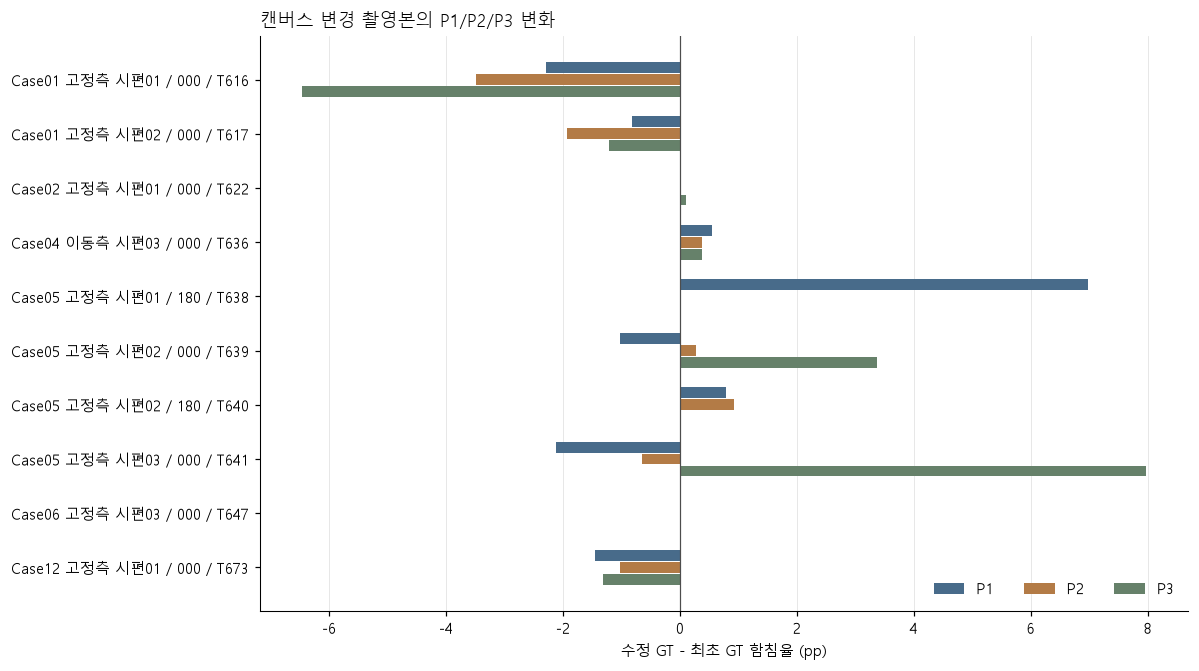

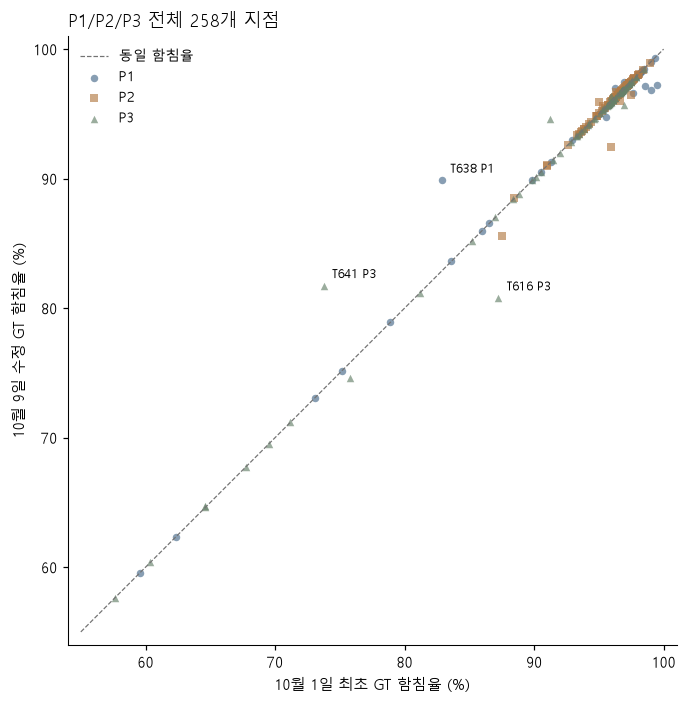

In [5]:
bar_data = changed_captures.reset_index(drop=True)
y = np.arange(len(bar_data))
fig, ax = plt.subplots(figsize=(11, 6.2))
for j, (point, color) in enumerate(zip(POINTS, POINT_COLORS)):
    ax.barh(y + (j - 1) * 0.22, bar_data[point], height=0.20, color=color, label=point)
labels = [f"Case{r.case_number:02d} {r.side} 시편{r.specimen_label} / {r.direction} / T{r.task_id}"
          for r in bar_data.itertuples()]
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.axvline(0, color="0.3", linewidth=0.8)
ax.grid(axis="x", color="0.88", linewidth=0.5)
ax.set_axisbelow(True)
ax.set_xlabel("수정 GT - 최초 GT 함침율 (pp)")
ax.set_title("캔버스 변경 촬영본의 P1/P2/P3 변화", loc="left", fontsize=12)
ax.legend(frameon=False, ncol=3, loc="lower right")
fig.tight_layout()
show_figure(fig, "05_p123_signed_change")

fig, ax = plt.subplots(figsize=(7, 6.5))
lo = math.floor(min(points["training_gt_pct"].min(), points["download_gt_pct"].min()) / 5) * 5
ax.plot([lo, 100], [lo, 100], color="0.45", linewidth=0.8, linestyle="--", label="동일 함침율")
for point, color, marker in zip(POINTS, POINT_COLORS, ["o", "s", "^"]):
    group = points[points["point"] == point]
    ax.scatter(group["training_gt_pct"], group["download_gt_pct"],
               color=color, marker=marker, s=24, alpha=0.65, linewidths=0, label=point)
for row in points.nlargest(3, "changed_pixels").itertuples():
    ax.annotate(f"T{row.task_id} {row.point}", (row.training_gt_pct, row.download_gt_pct),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xlim(lo - 1, 101); ax.set_ylim(lo - 1, 101)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("10월 1일 최초 GT 함침율 (%)")
ax.set_ylabel("10월 9일 수정 GT 함침율 (%)")
ax.set_title("P1/P2/P3 전체 258개 지점", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
show_figure(fig, "06_gt_rate_scatter")

## 원본과 마스크

`MASK_TASKS`에서 볼 촬영본을 지정한다. 원본·최초 GT·수정 GT·추가/제거를 Matplotlib로 다시 그린다.
최초 데이터 폴더 정리의 영향을 피하기 위해, 비교 당시 저장·검증한 그림의 **원래 256×256 패널**을 읽는다.
각 패널의 픽셀 수와 추가/제거 픽셀을 JSON 기록에 다시 대조한다. 확대 보간은 사용하지 않는다.

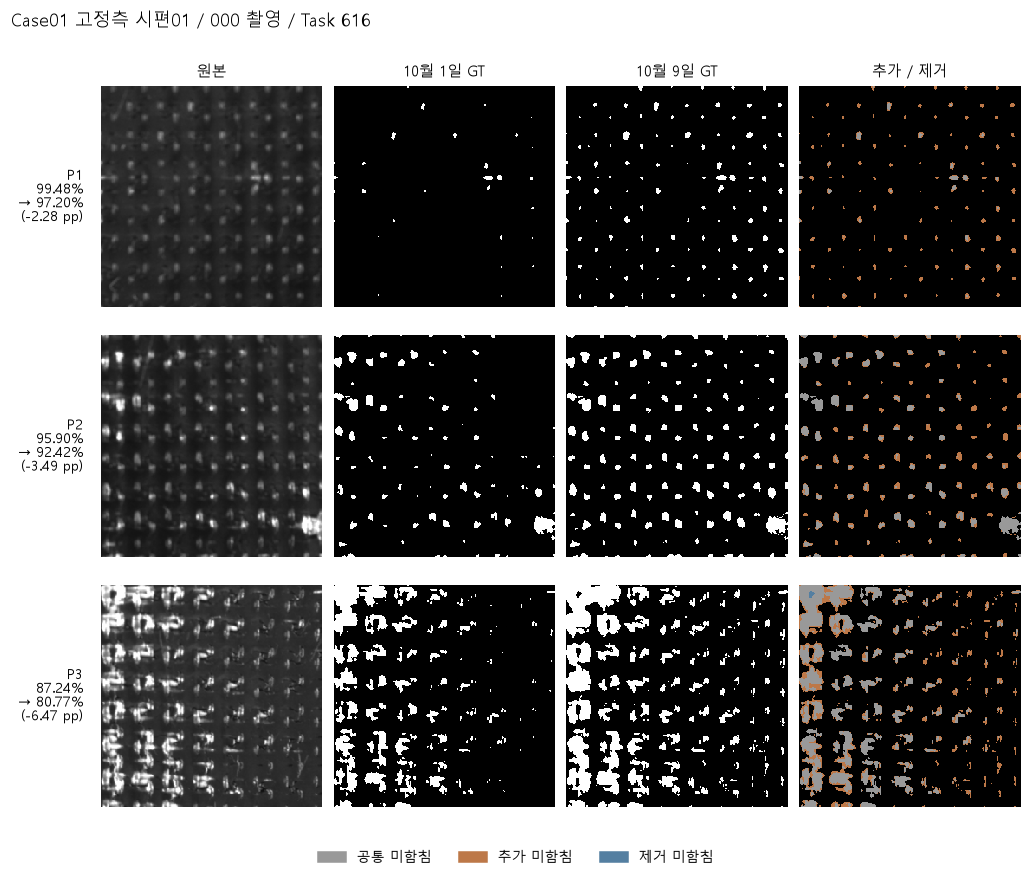

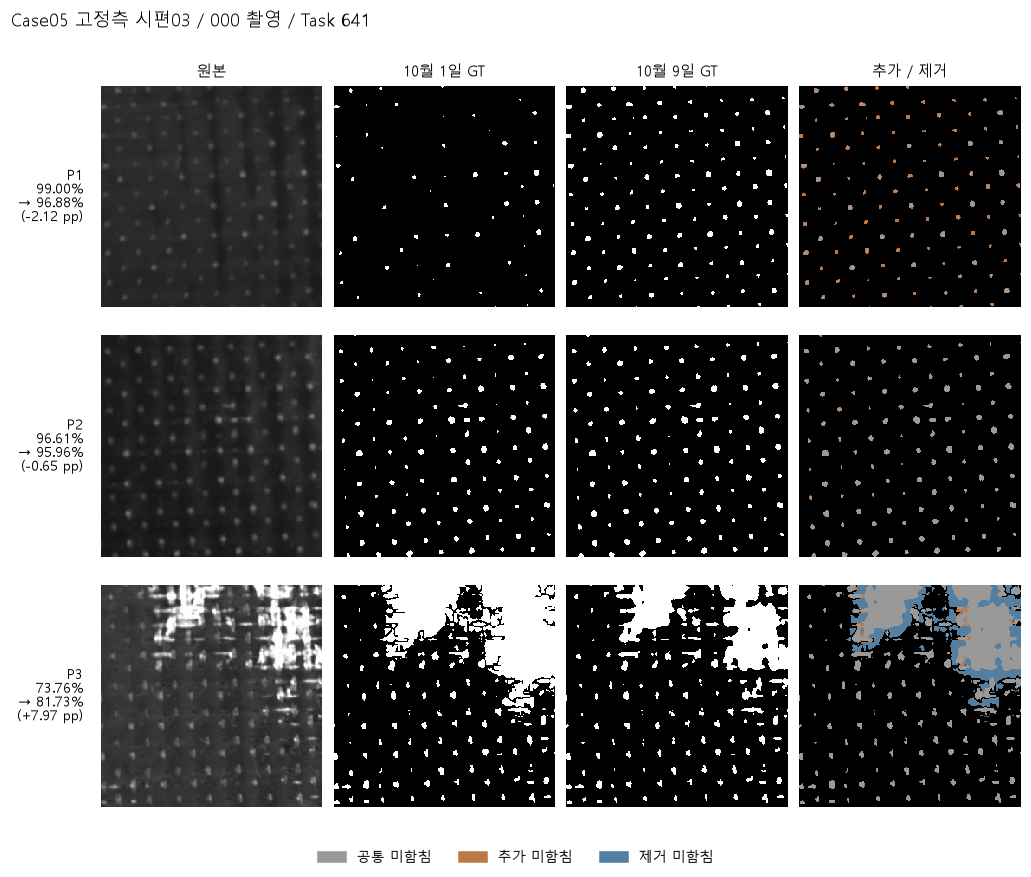

In [6]:
def archived_panels(task_id):
    records = points[points["task_id"] == task_id].set_index("point", drop=False).reindex(POINTS)
    if records["task_id"].isna().any():
        raise ValueError(f"Task {task_id}: P1/P2/P3 기록이 없습니다.")
    path = SOURCE / "figures" / f"task_{task_id}_P123.png"
    with Image.open(path) as image:
        canvas = np.asarray(image.convert("RGB"))
    if canvas.shape != (1150, 1410, 3):
        raise ValueError(f"저장된 native 패널 형식이 달라졌습니다: {path}")
    result = []
    for i, point in enumerate(POINTS):
        row = records.loc[point]
        y = 126 + i * 344
        panels = [canvas[y:y + 256, x:x + 256].copy() for x in [20, 298, 576, 854]]
        original, old_rgb, previous_rgb, new_rgb = panels
        for panel in [old_rgb, previous_rgb, new_rgb]:
            assert np.isin(panel, [0, 255]).all()
            assert np.array_equal(panel[:, :, 0], panel[:, :, 1])
            assert np.array_equal(panel[:, :, 0], panel[:, :, 2])
        old = old_rgb[:, :, 0] > 0
        previous = previous_rgb[:, :, 0] > 0
        new = new_rgb[:, :, 0] > 0
        added, removed = new & ~old, old & ~new
        assert int(old.sum()) == row["old_exposure_pixels"]
        assert int(new.sum()) == row["new_exposure_pixels"]
        assert int(added.sum()) == row["added_exposure_pixels"]
        assert int(removed.sum()) == row["removed_exposure_pixels"]
        assert np.array_equal(previous, new)
        result.append((row, original, old, new, added, removed))
    return result

mask_source_hashes = {}
for task_id in MASK_TASKS:
    rows = archived_panels(task_id)
    mask_source_hashes[str(task_id)] = file_hash(SOURCE / "figures" / f"task_{task_id}_P123.png")
    first = rows[0][0]
    fig, axes = plt.subplots(3, 4, figsize=(10.2, 8))
    for i, (row, original, old, new, added, removed) in enumerate(rows):
        difference = np.zeros((256, 256, 3), dtype=np.float32)
        difference[old & new] = [0.6, 0.6, 0.6]
        difference[added] = plt.matplotlib.colors.to_rgb(ADDED_COLOR)
        difference[removed] = plt.matplotlib.colors.to_rgb(REMOVED_COLOR)
        for j, panel in enumerate([original, old, new, difference]):
            axes[i, j].imshow(panel, cmap="gray", vmin=0, vmax=255 if j == 0 else 1,
                               interpolation="nearest")
            axes[i, j].set_axis_off()
        axes[i, 0].text(-0.08, 0.5,
                       f"{row['point']}\n{row['training_gt_pct']:.2f}%\n→ {row['download_gt_pct']:.2f}%\n({row['download_minus_training_pp']:+.2f} pp)",
                       transform=axes[i, 0].transAxes, ha="right", va="center", fontsize=9)
    for ax, title in zip(axes[0], ["원본", "10월 1일 GT", "10월 9일 GT", "추가 / 제거"]):
        ax.set_title(title, fontsize=10)
    fig.suptitle(f"Case{first['case_number']:02d} {first['side']} 시편{first['specimen_label']} / "
                 f"{first['direction']} 촬영 / Task {task_id}", fontsize=12, x=0.08, ha="left")
    fig.legend(handles=[Patch(color="0.6", label="공통 미함침"),
                        Patch(color=ADDED_COLOR, label="추가 미함침"),
                        Patch(color=REMOVED_COLOR, label="제거 미함침")],
               loc="lower center", ncol=3, frameon=False, fontsize=9)
    fig.subplots_adjust(left=0.16, right=0.98, top=0.9, bottom=0.07, wspace=0.05, hspace=0.08)
    show_figure(fig, f"07_masks_task{task_id}")

## 같은 A 모델 예측에 GT만 바꿔 적용한 참고 결과

당시 저장된 예측을 사용한다. 모델을 다시 학습하거나 추론한 결과가 아니다.
Test 유효 타일 252개와 000 방향 중앙 27개를 구분하며, 이 수치를 현재 v3/Gold72의 성능으로 해석하지 않는다.
Dice/IoU는 전체 픽셀 합산, 함침율 MAE는 이미지별 절대오차 평균이다.

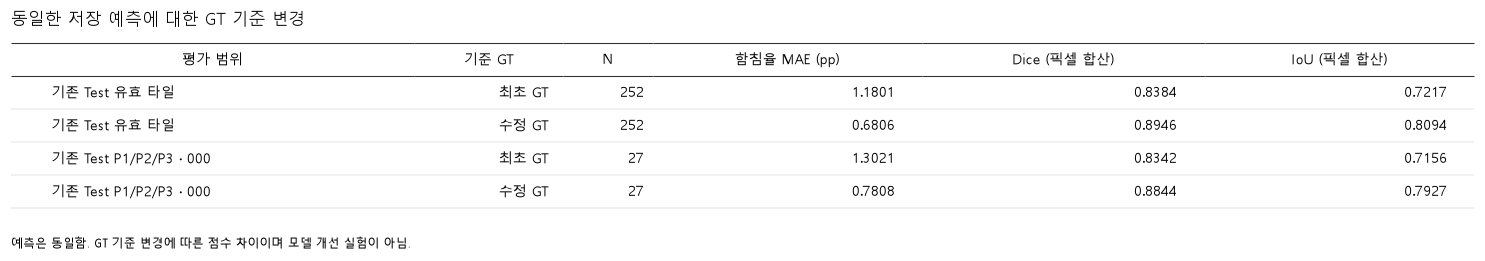

In [7]:
model_rows = []
for label, key, frame in [
    ("기존 Test 유효 타일", "test_valid_tiles", tiles[tiles["split"] == "test"]),
    ("기존 Test P1/P2/P3 · 000", "test_central_000",
     points[(points["split"] == "test") & (points["direction"] == "000")]),
]:
    assert frame["old_pred_pct"].notna().all() and frame["download_pred_pct"].notna().all()
    np.testing.assert_allclose(frame["old_pred_pct"], frame["download_pred_pct"])
    for prefix, version, saved_key in [("old", "최초 GT", "old"), ("download", "수정 GT", "download")]:
        tp, fp, fn = (float(frame[f"{prefix}_{name}"].sum()) for name in ["tp", "fp", "fn"])
        dice = 2 * tp / (2 * tp + fp + fn)
        iou = tp / (tp + fp + fn)
        mae = float(frame[f"{prefix}_absolute_error_pp"].mean())
        saved = summary["saved_prediction_evaluation"][key][saved_key]
        np.testing.assert_allclose([mae, dice, iou],
            [saved["mean_absolute_error_pp"], saved["micro_dice"], saved["micro_iou"]], atol=1e-12)
        model_rows.append({"평가 범위": label, "기준 GT": version, "N": len(frame),
                           "함침율 MAE (pp)": mae, "Dice (픽셀 합산)": dice, "IoU (픽셀 합산)": iou})
model_table = pd.DataFrame(model_rows)
plot_table(model_table, "동일한 저장 예측에 대한 GT 기준 변경", "08_fixed_prediction_reference", width=14,
           note="예측은 동일함. GT 기준 변경에 따른 점수 차이이며 모델 개선 실험이 아님.")

## 전체 촬영본 표

86개 촬영본을 Case·측·시편·촬영 방향 순서로 정렬한다. 표는 24행씩 나누고, 전체 수치는 CSV로 저장한다.

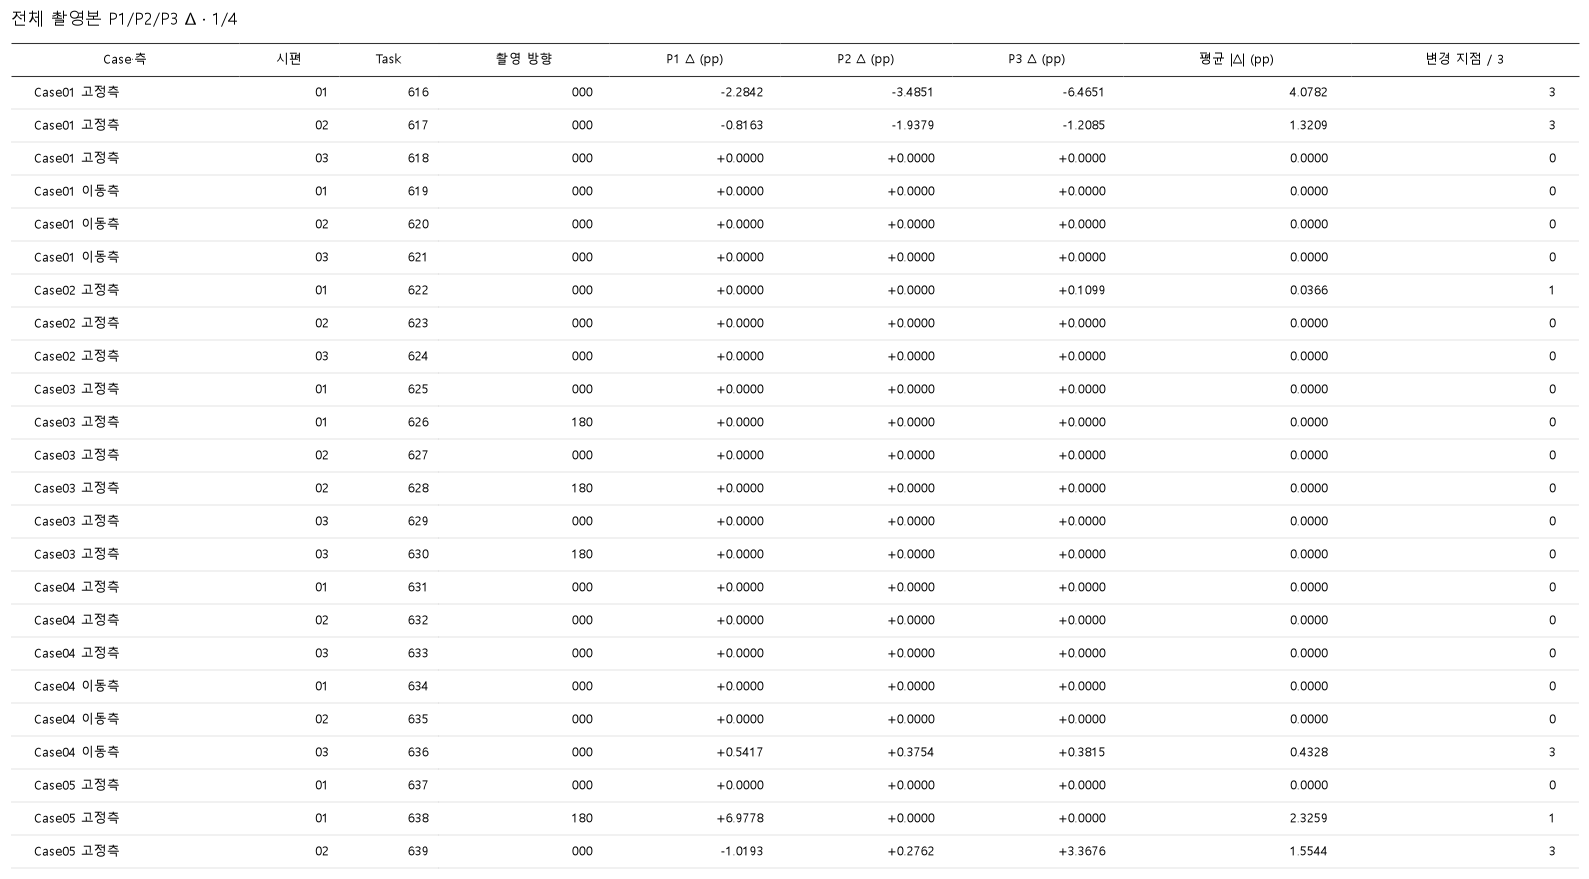

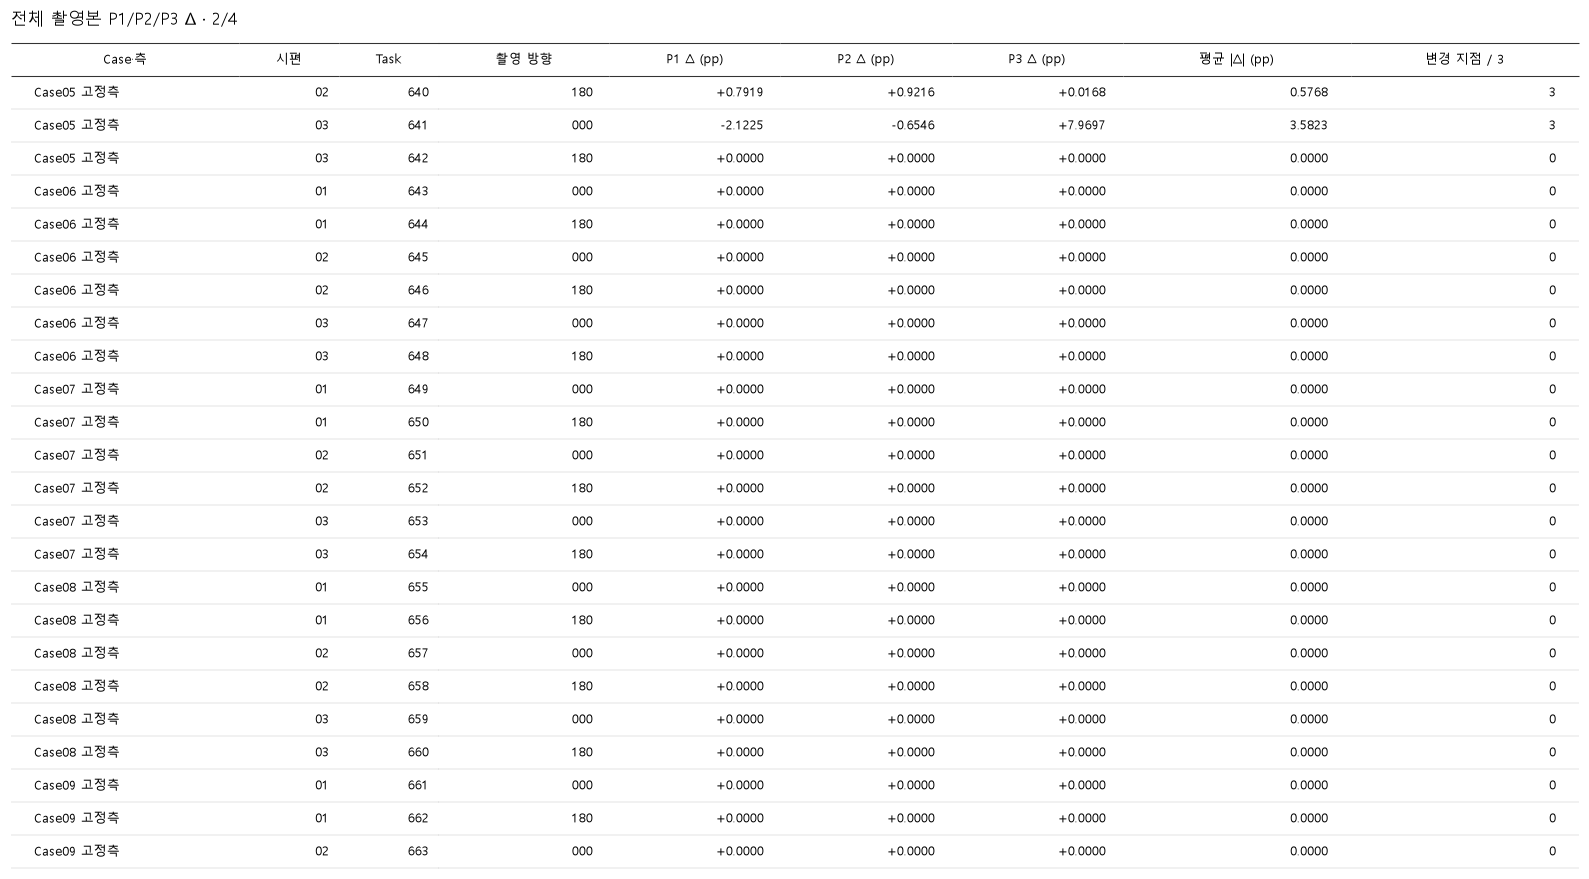

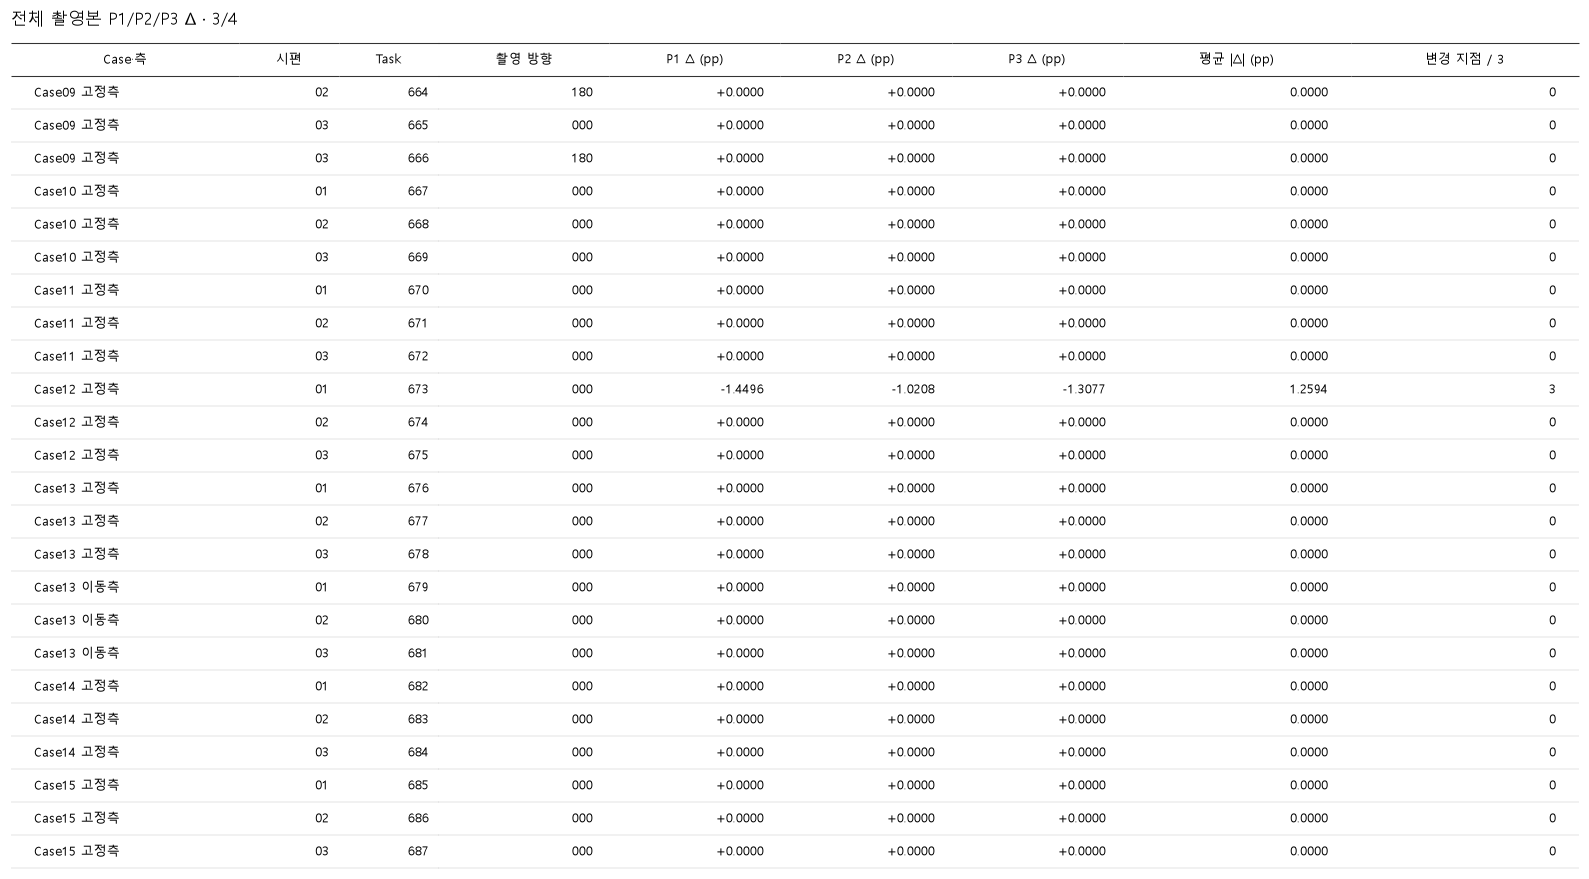

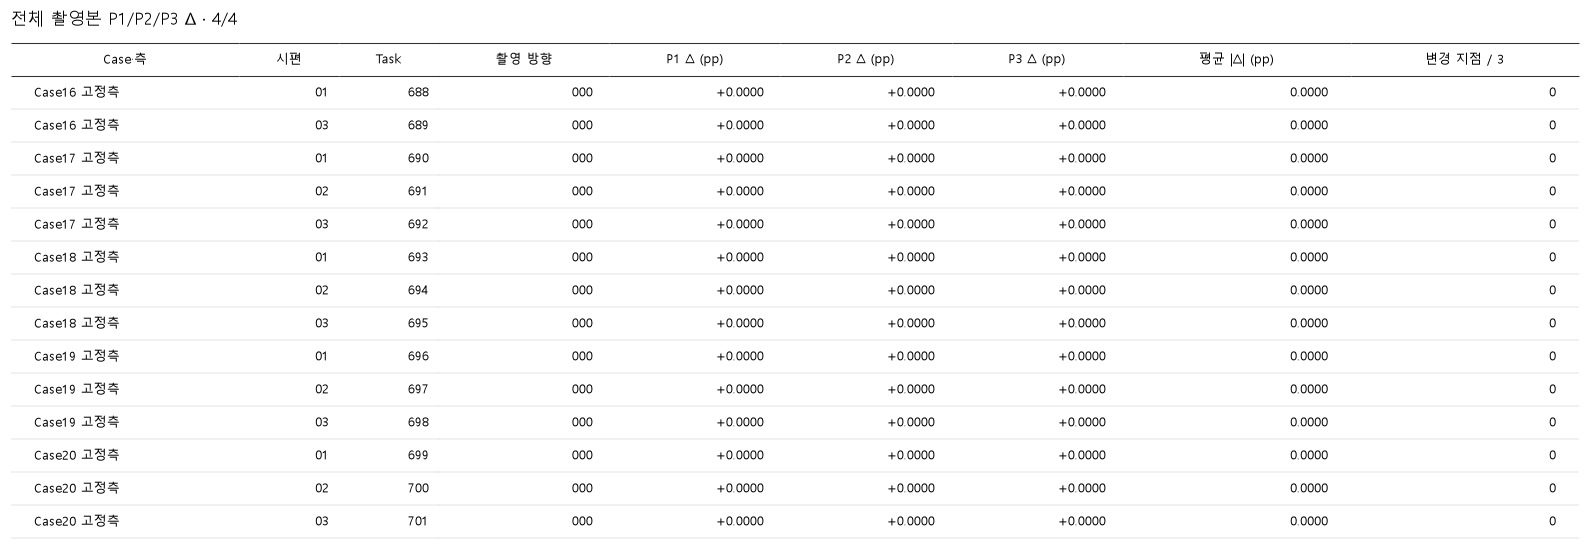

In [8]:
all_capture_table = capture_frame(capture_data)
if SHOW_ALL_CAPTURE_TABLES:
    pages = math.ceil(len(all_capture_table) / ROWS_PER_PAGE)
    for page in range(pages):
        page_data = all_capture_table.iloc[page * ROWS_PER_PAGE:(page + 1) * ROWS_PER_PAGE]
        plot_table(page_data, f"전체 촬영본 P1/P2/P3 Δ · {page + 1}/{pages}",
                   f"09_all_captures_page{page + 1:02d}", width=15, formats=delta_formats, font_size=8.5)

In [9]:
OUT.mkdir(parents=True, exist_ok=True)
tables = {
    "gt_versions": version_table,
    "scope_summary": scope_table,
    "changed_captures": changed_capture_table,
    "changed_point_values": point_table,
    "all_captures": all_capture_table,
    "fixed_prediction_reference": model_table,
}
for name, frame in tables.items():
    frame.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")
points.to_csv(OUT / "all_258_point_values.csv", index=False, encoding="utf-8-sig")
assert all(file_hash(SOURCE / name) == digest for name, digest in SOURCE_HASHES.items())
provenance = {
    "source": str(SOURCE), "source_json_sha256": SOURCE_HASHES,
    "historical_snapshot_utc": summary["created_at_utc"],
    "mask_rule": "Exposure = alpha > 0; native pixels = 65536 per tile",
    "delta_rule": "downloaded revised GT minus original training GT, in pp",
    "captures": len(tasks), "valid_tiles": len(tiles), "central_points": len(points),
    "changed_captures": len(changed_captures), "changed_central_points": len(changed_points),
    "archived_mask_panels_sha256": mask_source_hashes,
    "previous_json_equals_download_gt": True,
    "fixed_model_metrics_independently_recalculated": True,
    "source_files_unchanged": True,
    "central_image_pair_changed_pixels": int(points["image_changed_pixels"].sum()),
    "valid_tile_image_pair_changed_pixels": int(tiles["image_changed_pixels"].sum()),
}
(OUT / "provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"표·그림 저장 위치: {OUT}")
print("PNG 300 dpi / PDF / CSV. 입력 데이터와 라벨은 변경하지 않음.")

표·그림 저장 위치: D:\Code\vision_data\analysis\261012\gt_revision_figures
PNG 300 dpi / PDF / CSV. 입력 데이터와 라벨은 변경하지 않음.
